<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 4. Artificial Neural Network with Backpropagation

This notebook demonstrates a multi-layer perceptron (Neural Network) built from scratch using `numpy`. We will implement the forward propagation, loss calculation, and backpropagation steps manually, and then evaluate the model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Set random seed for reproducibility
np.random.seed(42)


In [2]:
class NeuralNetwork:
    def __init__(self, layers, learning_rate=0.1):
        """
        layers: List containing the number of neurons in each layer. E.g., [2, 4, 1]
        """
        self.layers = layers
        self.lr = learning_rate
        self.weights = []
        self.biases = []

        # Initialize weights and biases
        for i in range(len(layers) - 1):
            # Xavier/He-like initialization
            w = np.random.randn(layers[i], layers[i+1]) * np.sqrt(2.0 / layers[i])
            b = np.zeros((1, layers[i+1]))
            self.weights.append(w)
            self.biases.append(b)

    def sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def sigmoid_derivative(self, a):
        # derivative in terms of activation 'a' = sigmoid(z)
        return a * (1.0 - a)

    def forward(self, X):
        self.activations = [X]
        self.zs = []

        a = X
        for i in range(len(self.weights)):
            z = np.dot(a, self.weights[i]) + self.biases[i]
            self.zs.append(z)
            a = self.sigmoid(z)
            self.activations.append(a)
        return a

    def backward(self, y):
        # Number of samples
        m = y.shape[0]

        # Output layer error (using Binary Cross Entropy derivative combined with Sigmoid activation derivative)
        # dL/dz = a_last - y
        delta = self.activations[-1] - y

        # Keep track of gradients
        dw_list = []
        db_list = []

        # Backpropagate
        for i in reversed(range(len(self.weights))):
            # Weight gradient: transpose of activation(i) multiplied by current delta
            dw = np.dot(self.activations[i].T, delta) / m
            db = np.sum(delta, axis=0, keepdims=True) / m

            dw_list.insert(0, dw)
            db_list.insert(0, db)

            if i > 0:
                # Delta for next (previous) layer
                delta = np.dot(delta, self.weights[i].T) * self.sigmoid_derivative(self.activations[i])

        # Update weights and biases using gradient descent
        for i in range(len(self.weights)):
            self.weights[i] -= self.lr * dw_list[i]
            self.biases[i] -= self.lr * db_list[i]

    def train(self, X, y, epochs=1000):
        loss_history = []
        for epoch in range(epochs):
            output = self.forward(X)
            self.backward(y)

            # Binary Cross-Entropy Loss
            loss = -np.mean(y * np.log(output + 1e-15) + (1 - y) * np.log(1 - output + 1e-15))
            loss_history.append(loss)

            if (epoch + 1) % (epochs // 10) == 0 or epoch == 0:
                print(f"Epoch {epoch+1}/{epochs} - Loss: {loss:.4f}")
        return loss_history

    def predict(self, X):
        output = self.forward(X)
        return (output >= 0.5).astype(int)


In [3]:
# Generate a synthetic dataset (Moons)
X, y = make_moons(n_samples=500, noise=0.2, random_state=42)
y = y.reshape(-1, 1)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Define network layers: 2 inputs, 1 hidden layer with 5 nodes, and 1 output node
layers = [2, 5, 1]
nn = NeuralNetwork(layers, learning_rate=0.5)

# Train the network
history = nn.train(X_train, y_train, epochs=2000)


Epoch 1/2000 - Loss: 1.0078
Epoch 200/2000 - Loss: 0.2995
Epoch 400/2000 - Loss: 0.2905
Epoch 600/2000 - Loss: 0.2889
Epoch 800/2000 - Loss: 0.2879
Epoch 1000/2000 - Loss: 0.2871
Epoch 1200/2000 - Loss: 0.2866
Epoch 1400/2000 - Loss: 0.2861
Epoch 1600/2000 - Loss: 0.2857
Epoch 1800/2000 - Loss: 0.2853
Epoch 2000/2000 - Loss: 0.2850



Test Accuracy: 86.00%


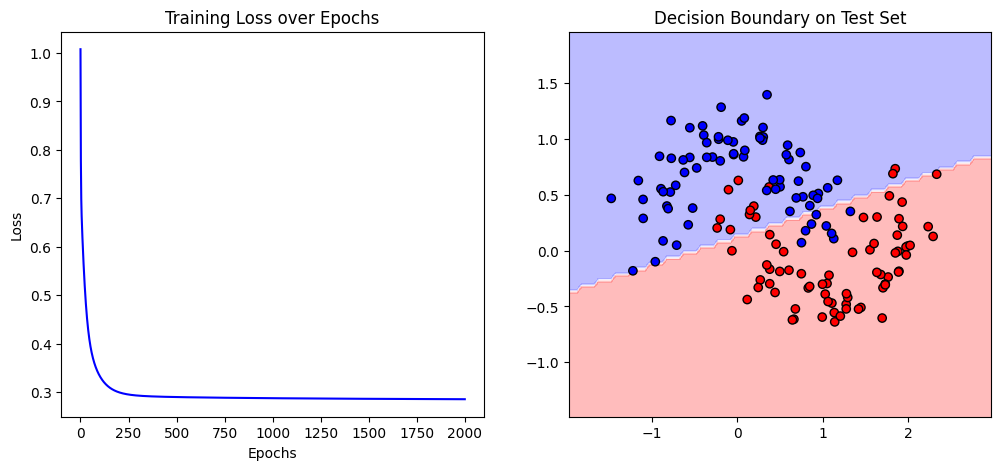

In [4]:
# Evaluate the model
y_pred = nn.predict(X_test)
accuracy = np.mean(y_pred == y_test) * 100
print(f"\nTest Accuracy: {accuracy:.2f}%")

# Plot loss history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history, color='blue')
plt.title('Training Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')

# Plot Decision Boundary
plt.subplot(1, 2, 2)
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = nn.predict(grid_points)
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap='bwr')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test.ravel(), cmap='bwr', edgecolor='k')
plt.title('Decision Boundary on Test Set')
plt.show()
